<a href="https://www.kaggle.com/code/stamkeenfatima/cdc-diabetes-health-analysis-by-deep-learning-mode?scriptVersionId=362572191" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/datascikhan/global-ai-jobs-2026/global_ai_jobs_2026.csv
/kaggle/input/datasets/abdelazizsami/cdc-diabetes-health-indicators/diabetes_binary_5050split_health_indicators_BRFSS2015.csv
/kaggle/input/datasets/abdelazizsami/cdc-diabetes-health-indicators/diabetes_binary_health_indicators_BRFSS2015.csv
/kaggle/input/datasets/abdelazizsami/cdc-diabetes-health-indicators/diabetes_012_health_indicators_BRFSS2015.csv


In [2]:
print(os.listdir("/kaggle/input"))

['notebooks', 'datasets']


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Files:", files)

Folder: /kaggle/input
Files: []
Folder: /kaggle/input/notebooks
Files: []
Folder: /kaggle/input/notebooks/stamkeenfatima
Files: []
Folder: /kaggle/input/notebooks/stamkeenfatima/notebook8495f3de78
Files: []
Folder: /kaggle/input/datasets
Files: []
Folder: /kaggle/input/datasets/datascikhan
Files: []
Folder: /kaggle/input/datasets/datascikhan/global-ai-jobs-2026
Files: ['global_ai_jobs_2026.csv']
Folder: /kaggle/input/datasets/abdelazizsami
Files: []
Folder: /kaggle/input/datasets/abdelazizsami/cdc-diabetes-health-indicators
Files: ['diabetes_binary_5050split_health_indicators_BRFSS2015.csv', 'diabetes_binary_health_indicators_BRFSS2015.csv', 'diabetes_012_health_indicators_BRFSS2015.csv']
Folder: /kaggle/input/datasets/desertman
Files: []
Folder: /kaggle/input/datasets/desertman/komp-plasma-metabolomics-dataset
Files: ['KOMP_data_matrix.xlsx', 'Steroids_Bile_Acid_multi_quant_method_details.xlsx', 'Steroids_Bile_Acid_details.xlsx', 'KOMP_internal_standards.xlsx', 'KOMP_data_dictionary.x

# Data Preprocessing

In [4]:
import pandas as pd
df = pd.read_csv( "/kaggle/input/datasets/abdelazizsami/cdc-diabetes-health-indicators/diabetes_binary_health_indicators_BRFSS2015.csv")                    

In [5]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [6]:
df.shape

(253680, 22)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

# Missing Value Analysis

In [8]:
df.isnull().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(24206)

In [10]:
("Percentage:", df.duplicated().mean() * 100)

('Percentage:', np.float64(9.541942604856512))

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print("New dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

New dataset shape: (229474, 22)
Remaining duplicates: 0


In [12]:
print(df["Diabetes_binary"].value_counts())

Diabetes_binary
0.0    194377
1.0     35097
Name: count, dtype: int64


In [13]:
print("\nPercentage of each class:")
print(df["Diabetes_binary"].value_counts(normalize=True) * 100)


Percentage of each class:
Diabetes_binary
0.0    84.705457
1.0    15.294543
Name: proportion, dtype: float64


# Import Train-Test Model

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"].astype(int)

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(  X, y,  test_size=0.2,random_state=42,
    stratify=y)

# Scale using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (183579, 21)
Testing data: (45895, 21)


# TensorFlow for Deep-Learning Analysis

In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
# Build neural network
model = Sequential([Input(shape=(X_train.shape[1],)),
                    Dense(32, activation="relu"), Dropout(0.2),
                    Dense(16, activation="relu"),
                    Dense(1, activation="sigmoid")])
# Compile model
model.compile( optimizer="adam", loss="binary_crossentropy", metrics=[  "accuracy",
        tf.keras.metrics.AUC(name="auc")])

model.summary()

2026-10-26 17:17:02.664821: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
#Dense(32) and Dense(16) learn patterns in the clinical measurements.
#Dropout(0.2) helps reduce overfitting.
#sigmoid produces a probability between 0 and 1.
#binary_crossentropy measures the error for binary classification.

In [17]:
history = model.fit( X_train,  y_train,  validation_split=0.2,   epochs=15,   batch_size=64,
    verbose=1)

Epoch 1/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8437 - auc: 0.7817 - loss: 0.3608 - val_accuracy: 0.8509 - val_auc: 0.8101 - val_loss: 0.3447
Epoch 2/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8510 - auc: 0.8073 - loss: 0.3440 - val_accuracy: 0.8519 - val_auc: 0.8129 - val_loss: 0.3423
Epoch 3/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8518 - auc: 0.8096 - loss: 0.3423 - val_accuracy: 0.8517 - val_auc: 0.8135 - val_loss: 0.3420
Epoch 4/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8525 - auc: 0.8112 - loss: 0.3413 - val_accuracy: 0.8517 - val_auc: 0.8138 - val_loss: 0.3419
Epoch 5/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8524 - auc: 0.8121 - loss: 0.3407 - val_accuracy: 0.8520 - val_auc: 0.8136 - val_loss: 0.3417
Epoch 6/15
2295/2295 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8536 - auc: 0.8128 - loss: 0.3402 - val_accuracy: 0.8522 - val_auc: 0.8138 - val_loss: 0.3418
Epoch 7/15
2295/2295 ━━━━━━━

# Results

# Accuracy Test

In [18]:
test_loss, test_accuracy, test_auc = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test AUC:", test_auc)

Test Loss: 0.3381875455379486
Test Accuracy: 0.8524240255355835
Test AUC: 0.8178278207778931


# Confusion-Matrix

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

1435/1435 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
              precision    recall  f1-score   support

           0       0.86      0.99      0.92     38876
           1       0.67      0.07      0.13      7019

    accuracy                           0.85     45895
   macro avg       0.76      0.53      0.52     45895
weighted avg       0.83      0.85      0.80     45895

Confusion Matrix:
[[38630   246]
 [ 6527   492]]


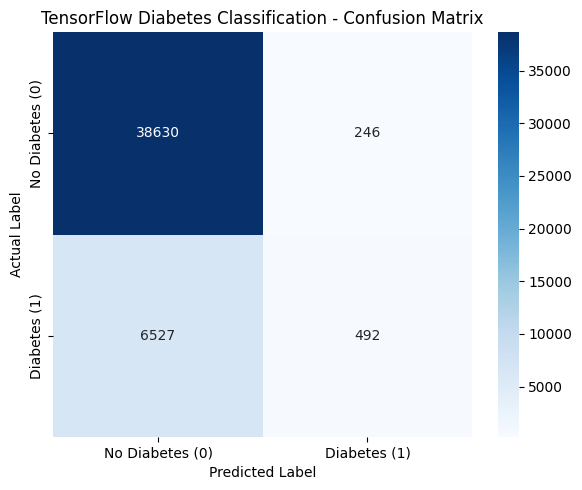

<Figure size 640x480 with 0 Axes>

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap( cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes (0)", "Diabetes (1)"],
    yticklabels=["No Diabetes (0)", "Diabetes (1)"])
plt.title("TensorFlow Diabetes Classification - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()
plt.savefig("/kaggle/working/confusion_matrix.png",dpi=300, bbox_inches="tight")
plt.show()

In [21]:

#Accuracy (85.36%): Most test records were classified correctly.
# AUC (0.8184): The model shows good ability to rank diabetes cases above non-diabetes cases.
#Loss (0.3384): This is the mo'# binary classification loss; it is most useful when comparing different model versions.

In [22]:
from sklearn.metrics import classification_report
print(classification_report(  y_test,  y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.86      0.99      0.92     38876
    Diabetes       0.67      0.07      0.13      7019

    accuracy                           0.85     45895
   macro avg       0.76      0.53      0.52     45895
weighted avg       0.83      0.85      0.80     45895



#  Conclusion

A TensorFlow neural network was developed to classify diabetes status using the CDC Diabetes Health Indicators dataset. The model achieved a test accuracy of **85.36%**, an AUC of **0.8184**, and a test loss of **0.3384**. However, diabetes-class recall was only **14%**, indicating that the model missed many diabetes-positive cases at the selected prediction threshold. This project demonstrates the application of data preprocessing, neural network training, and classification evaluation. Further optimization is needed before the model could be considered useful for diabetes screening.
